In [1]:
# Basic Libraries
import numpy as np
import pandas as pd

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:


#!pip install pydot
#!pip install tensorflow==2.19.0


In [ ]:
#!pip install numpy==2.0.2

In [ ]:
#!pip install opencv-python==4.11.0.86

In [ ]:


#!pip install matplotlib==3.10.1
#!pip install pandas==2.2.3
#!pip install Keras==3.5.0
#!pip install scikit-learn==1.6.1
#!pip install Pillow==11.1.0
#!pip install seaborn==0.13.2

In [3]:
#Evaluation library
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV

In [16]:

# Deep Learning libraries

from keras.datasets import mnist


In [4]:
from tensorflow.keras import layers

In [7]:
import keras


In [9]:
from keras.models import Sequential


In [15]:
from tensorflow.keras.layers import Dense, Activation, Dropout

print("Dense:", Dense)
print("Activation:", Activation)
print("Dropout:", Dropout)

Dense: <class 'keras.src.layers.core.dense.Dense'>
Activation: <class 'keras.src.layers.activations.activation.Activation'>
Dropout: <class 'keras.src.layers.regularization.dropout.Dropout'>


In [17]:
(X_train_digit, y_train_digit), (X_test_digit, y_test_digit) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 102s 9us/step


In [20]:
from tensorflow.keras.utils import to_categorical

In [22]:
import tensorflow as tf
from scikeras.wrappers import KerasClassifier

print("TensorFlow:", tf.__version__)
print("KerasClassifier imported successfully!")

TensorFlow: 2.19.0
KerasClassifier imported successfully!


In [23]:
 y_test_digit[3]

np.uint8(0)

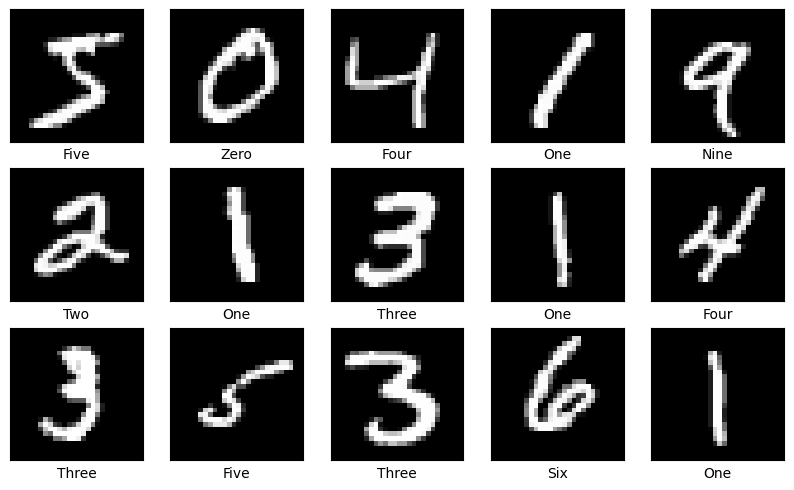

In [24]:
#Names of numbers in the dataset in order
col_names = ['Zero','One','Two','Three','Four','Five','Six','Seven','Eight','Nine']

#Visualizing the digits
plt.figure(figsize=(10,10))
for i in range(15):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(X_train_digit[i], cmap='gray')
    plt.xlabel(col_names[y_train_digit[i]])
plt.show()

In [25]:
X_train_digit.shape

(60000, 28, 28)

In [26]:
X_train_digit = X_train_digit.reshape(60000, 784)
X_test_digit = X_test_digit.reshape(10000, 784)

In [27]:
y_test_digit

array([7, 2, 1, ..., 4, 5, 6], dtype=uint8)

In [28]:
#Encoding Digit MNIST Labels
y_train_digit = to_categorical(y_train_digit, num_classes=10)

y_test_digit = to_categorical(y_test_digit, num_classes=10)

In [29]:
y_train_digit

array([[0., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 1., 0.]])

In [30]:
#Creating base neural network
model = keras.Sequential([
    layers.Dense(256, activation='relu', input_shape=(784,)),
    #layers.Dropout(0.3),
    #layers.BatchNormalization(),
    layers.Dense(64, activation='relu'),
    #layers.Dropout(0.3),
    #layers.BatchNormalization(),
    layers.Dense(64, activation='relu'),
    #layers.Dropout(0.3),
    #layers.BatchNormalization(),
    layers.Dense(10,activation='sigmoid'),
])

C:\Users\Lenovo\anaconda3\envs\aidl\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [31]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 256)                 │         200,960 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │          16,448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 222,218 (868.04 KB)

 Trainable params: 222,218 (868.04 KB)

 Non-trainable params: 0 (0.00 B)

In [32]:
#Compiling the model
model.compile(loss="categorical_crossentropy",
              optimizer="adam",
              metrics = ['accuracy'])

In [33]:
history=model.fit(X_train_digit, y_train_digit, batch_size=100, epochs=10,validation_data=(X_test_digit, y_test_digit))

Epoch 1/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 39s 8ms/step - accuracy: 0.7115 - loss: 1.2701 - val_accuracy: 0.8339 - val_loss: 0.3594
Epoch 2/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.7987 - loss: 0.2782 - val_accuracy: 0.8253 - val_loss: 0.2724
Epoch 3/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.8105 - loss: 0.1943 - val_accuracy: 0.8033 - val_loss: 0.2490
Epoch 4/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.8066 - loss: 0.1611 - val_accuracy: 0.7942 - val_loss: 0.1825
Epoch 5/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.8045 - loss: 0.1386 - val_accuracy: 0.7675 - val_loss: 0.1922
Epoch 6/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.8016 - loss: 0.1225 - val_accuracy: 0.7656 - val_loss: 0.1681
Epoch 7/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.7979 - loss: 0.1040 - val_accuracy: 0.7847 - val_loss: 0.1806
Epoch 8/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.7762 - loss: 0.1006 - val_accuracy: 0

In [34]:
test_loss_digit, test_acc_digit = model.evaluate(X_test_digit, y_test_digit)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7811 - loss: 0.1503


In [35]:
print('Digit MNIST Test accuracy:', round(test_acc_digit,4))

Digit MNIST Test accuracy: 0.7811


In [36]:
#Predicting the labels-DIGIT
y_predict = model.predict(X_test_digit)


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [37]:
y_predict[0]

array([6.3941344e-03, 9.9972391e-01, 9.9989855e-01, 9.9996960e-01,
       5.8653390e-01, 9.9998337e-01, 1.2735831e-06, 1.0000000e+00,
       9.8801237e-01, 9.9999613e-01], dtype=float32)

In [38]:
y_predicts=np.argmax(y_predict, axis=1) # Here we get the index of maximum value in the encoded vector
y_test_digit_eval=np.argmax(y_test_digit, axis=1)

In [39]:
y_predicts[0]

np.int64(7)

In [40]:
y_test_digit_eval

array([7, 2, 1, ..., 4, 5, 6])

In [41]:
y_pre=pd.DataFrame(y_predicts)

In [42]:
y_pre

,0
0,7
1,2
2,1
3,0
4,4
...,...
9995,1
9996,3
9997,4
9998,1


In [43]:

y_test_digit_eval

array([7, 2, 1, ..., 4, 5, 6])

In [45]:
#Confusion matrix for Digit MNIST
con_mat=confusion_matrix(y_test_digit_eval,y_predicts)
plt.style.use('seaborn-deep')
plt.figure(figsize=(10,10))
sns.heatmap(con_mat,annot=True,annot_kws={'size': 15},linewidths=0.5,fmt="d",cmap="gray")
plt.title('True or False predicted digit MNIST\n',fontweight='bold',fontsize=15)
plt.show()

OSError: 'seaborn-deep' is not a valid package style, path of style file, URL of style file, or library style name (library styles are listed in `style.available`)

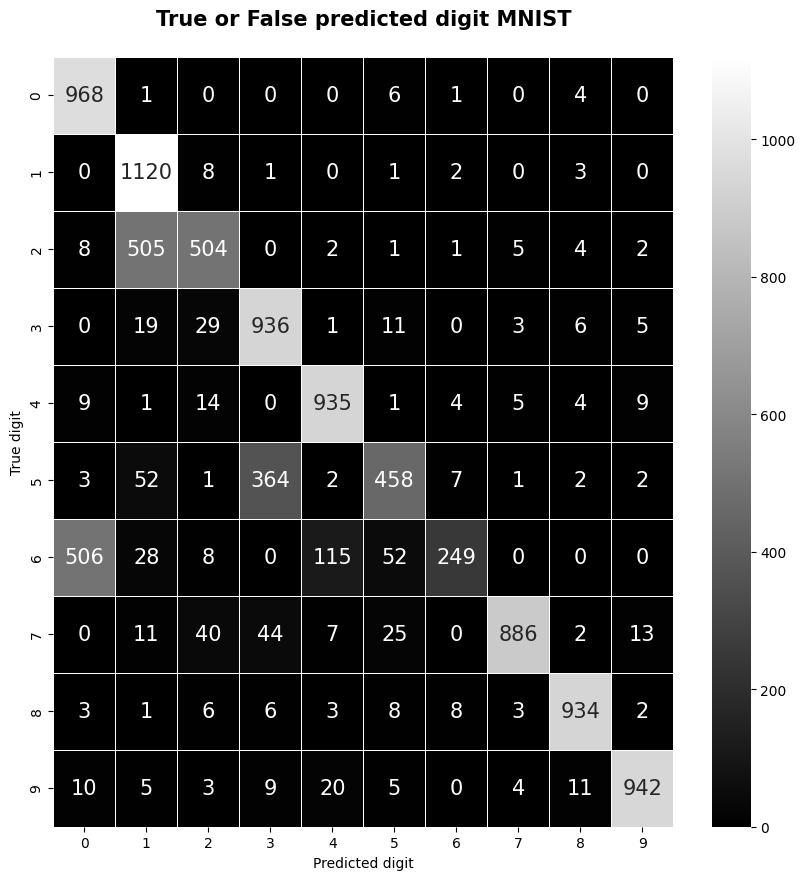

In [46]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Confusion matrix for Digit MNIST
con_mat = confusion_matrix(y_test_digit_eval, y_predicts)

plt.style.use('seaborn-v0_8-deep')
plt.figure(figsize=(10, 10))

sns.heatmap(
    con_mat,
    annot=True,
    annot_kws={'size': 15},
    linewidths=0.5,
    fmt="d",
    cmap="gray"
)

plt.title(
    'True or False predicted digit MNIST\n',
    fontweight='bold',
    fontsize=15
)
plt.xlabel('Predicted digit')
plt.ylabel('True digit')
plt.show()


In [47]:
print(history.history.keys())


dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


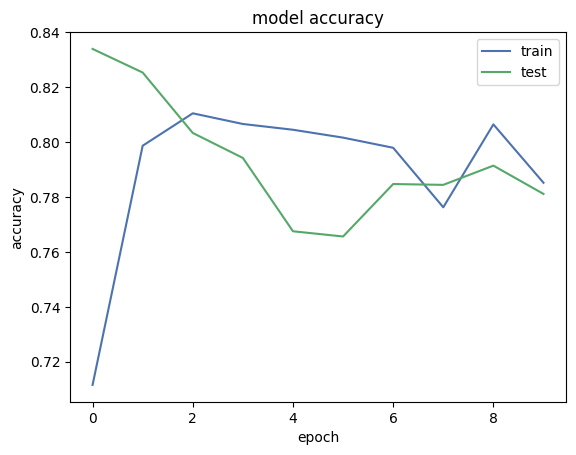

In [48]:
# summarize history for accuracy
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='best')
plt.show()


In [49]:
#tf.expand_dims(X_test_digit[0])
y_predict_single = model.predict(X_test_digit[[2]])
y_predicts_single=np.argmax(y_predict_single, axis=1) # Here we get the index of maximum value in the encoded vector
y_test_digit_eval=np.argmax(y_test_digit, axis=1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 181ms/step


In [50]:
y_predicts_single[0]

np.int64(1)

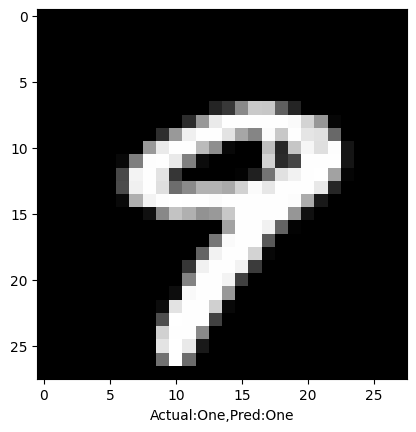

In [54]:
#Names of numbers in the dataset in order
col_names = ['Zero','One','Two','Three','Four','Five','Six','Seven','Eight','Nine']

#Visualizing the digits
#plt.figure(figsize=(10,10))
plt.imshow(X_test_digit[9].reshape(28,28), cmap='gray')
plt.xlabel("Actual:{},Pred:{}".format(col_names[np.argmax(y_test_digit[2])],col_names[y_predicts_single[0]]))
plt.show()

In [56]:
y_test_digit[9]

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 1.])